In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/WikiDT_Persistent/')
FULL_IMAGE_DIR = ROOT / 'data' / 'images'
SUB_IMAGE_DIR = ROOT / 'data' / 'detection' / 'images'
QA_DIR = ROOT / 'QA_image' / 'data' / 'Train'


Mounted at /content/drive


In [2]:
import pandas as pd

# Find and read the parquet file(s) in QA_DIR
parquet_files = list(QA_DIR.glob('*.parquet'))

if parquet_files:
    print(f"Reading parquet file: {parquet_files[0].name}")
    df = pd.read_parquet(parquet_files[0])
    display(df.head())
else:
    try:
        # Try loading the directory directly if parquet files are stored as partitioned dataset
        df = pd.read_parquet(QA_DIR)
        display(df.head())
    except Exception as e:
        print(f"Error reading parquet from {QA_DIR}: {e}")

Reading parquet file: data.parquet


,question,answer,context,pairs,positive_sentences,image
0,geno hayes and nick roach both played which po...,no answer,Position Player $ Free agency tag Date signed ...,"[{'label': 0, 'query': 'geno hayes and nick ro...",0,204_783_page.png
1,What is the number of bronze for Canada and si...,no answer,"Pos Team Time Gold Switzerland (Reto Götschi, ...","[{'label': 0, 'query': 'What is the number of ...",0,11338408_page.png
2,"What is Date, when Opponent is ""Philadelphia 7...",february 16,# Date H/A/N Opponent W/L Score Record 40 Janu...,"[{'label': 1, 'query': 'What is Date, when Opp...",1,16946097_page.png
3,Which Class has a Weight of 203?,sr,Position Number Name Height Weight Class Homet...,"[{'label': 1, 'query': 'Which Class has a Weig...",29,14624447_page.png
4,Who had 0 total votes in the purple team?,eliminated week 12 - the walk,Members Teammate Couples Team Blue Red 1 Blue ...,"[{'label': 1, 'query': 'Who had 0 total votes ...",1,18426579_page.png


In [3]:
import os

# Define the base path for images
IMAGE_BASE_PATH = '/content/drive/MyDrive/WikiDT_Persistent/data/images'

# Create the new column 'image_path' by joining the base path and the image filename
df['image_path'] = df['image'].apply(lambda x: os.path.join(IMAGE_BASE_PATH, str(x)) if pd.notnull(x) else None)

# Display the updated DataFrame to verify the new column
display(df[['image', 'image_path']].head())

,image,image_path
0,204_783_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,11338408_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
2,16946097_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
3,14624447_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
4,18426579_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...


In [4]:
# Show information about the columns (data types, non-null counts)
print("DataFrame Information:")
df.info()

# Display the first few rows showing all columns
print("\nFirst 5 rows of the full DataFrame:")
pd.set_option('display.max_columns', None)  # Ensure all columns are visible
display(df.head())

DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53492 entries, 0 to 53491
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   question            53492 non-null  object
 1   answer              53492 non-null  object
 2   context             53492 non-null  object
 3   pairs               53492 non-null  object
 4   positive_sentences  53492 non-null  int64 
 5   image               53492 non-null  object
 6   image_path          53492 non-null  object
dtypes: int64(1), object(6)
memory usage: 2.9+ MB

First 5 rows of the full DataFrame:


,question,answer,context,pairs,positive_sentences,image,image_path
0,geno hayes and nick roach both played which po...,no answer,Position Player $ Free agency tag Date signed ...,"[{'label': 0, 'query': 'geno hayes and nick ro...",0,204_783_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,What is the number of bronze for Canada and si...,no answer,"Pos Team Time Gold Switzerland (Reto Götschi, ...","[{'label': 0, 'query': 'What is the number of ...",0,11338408_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
2,"What is Date, when Opponent is ""Philadelphia 7...",february 16,# Date H/A/N Opponent W/L Score Record 40 Janu...,"[{'label': 1, 'query': 'What is Date, when Opp...",1,16946097_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
3,Which Class has a Weight of 203?,sr,Position Number Name Height Weight Class Homet...,"[{'label': 1, 'query': 'Which Class has a Weig...",29,14624447_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
4,Who had 0 total votes in the purple team?,eliminated week 12 - the walk,Members Teammate Couples Team Blue Red 1 Blue ...,"[{'label': 1, 'query': 'Who had 0 total votes ...",1,18426579_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...


In [5]:
# Define the save directory path
save_dir = ROOT / 'QA_image' / 'data' / 'Train'

# Ensure the target directory exists
save_dir.mkdir(parents=True, exist_ok=True)

# Define the output file path
output_file_path = save_dir / 'train_data_with_paths.parquet'

# Save the DataFrame to Parquet format
df.to_parquet(output_file_path, index=False)
print(f"DataFrame successfully saved to {output_file_path}")

DataFrame successfully saved to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Train/train_data_with_paths.parquet


In [6]:
import os
import pandas as pd

# Base image path
IMAGE_BASE_PATH = '/content/drive/MyDrive/WikiDT_Persistent/data/images'

# Define paths for Test and Val
test_dir = ROOT / 'QA_image' / 'data' / 'Test'
val_dir = ROOT / 'QA_image' / 'data' / 'Val'

for name, directory in [('Test', test_dir), ('Val', val_dir)]:
    # Find parquet files
    files = list(directory.glob('*.parquet'))
    if not files:
        print(f"No parquet file found in {directory}, trying directory direct load...")
        try:
            df_temp = pd.read_parquet(directory)
        except Exception as e:
            print(f"Could not load {name}: {e}")
            continue
    else:
        print(f"Reading parquet file for {name}: {files[0].name}")
        df_temp = pd.read_parquet(files[0])

    # Add the full image_path column
    df_temp['image_path'] = df_temp['image'].apply(lambda x: os.path.join(IMAGE_BASE_PATH, str(x)) if pd.notnull(x) else None)

    # Save the updated DataFrame in parquet format within its directory
    output_path = directory / 'data_with_paths.parquet'
    df_temp.to_parquet(output_path, index=False)
    print(f"Successfully saved {name} dataframe with image paths to {output_path}\n")

    # Store in global namespace as df_test and df_val
    if name == 'Test':
        df_test = df_temp
    else:
        df_val = df_temp

# Display the top rows of the processed Test DataFrame
print("Test DataFrame Preview:")
display(df_test.head(2))

# Display the top rows of the processed Val DataFrame
print("\nValidation DataFrame Preview:")
display(df_val.head(2))

Reading parquet file for Test: data.parquet
Successfully saved Test dataframe with image paths to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Test/data_with_paths.parquet

Reading parquet file for Val: data.parquet
Successfully saved Val dataframe with image paths to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Val/data_with_paths.parquet

Test DataFrame Preview:


,question,answer,context,pairs,positive_sentences,image,image_path
0,What are the title(s) of episodes directed by ...,buffy vs. dracula,No. overall No. in season Title Directed by Wr...,"[{'label': 0, 'query': 'What are the title(s) ...",1,28195971_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,who was the top driver at the 1967 british gra...,no answer,Pos No Driver Constructor Laps Time/Retired Gr...,"[{'label': 0, 'query': 'who was the top driver...",0,204_641_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...



Validation DataFrame Preview:


,question,answer,context,pairs,positive_sentences,image,image_path
0,when was the last year they placed 2nd?,no answer,No. Pos. Nation Player No. Pos. Nation Player ...,"[{'label': 0, 'query': 'when was the last year...",0,204_974_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...
1,What was the sensor resolution with a minimal ...,355x288,"Stable release v2.2/October 7, 2008 Operating ...","[{'label': 0, 'query': 'What was the sensor re...",2,13751214_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...


In [7]:
# Save the Test DataFrame with the specific filename
test_output_file = test_dir / 'test_data_with_paths.parquet'
df_test.to_parquet(test_output_file, index=False)
print(f"Test DataFrame successfully saved to {test_output_file}")

# Save the Val DataFrame with the specific filename
val_output_file = val_dir / 'val_data_with_paths.parquet'
df_val.to_parquet(val_output_file, index=False)
print(f"Validation DataFrame successfully saved to {val_output_file}")

Test DataFrame successfully saved to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Test/test_data_with_paths.parquet
Validation DataFrame successfully saved to /content/drive/MyDrive/WikiDT_Persistent/QA_image/data/Val/val_data_with_paths.parquet


In [8]:

%pip -q install transformers torch torchvision pillow pyarrow tqdm

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/WikiDT_Persistent")
FULL_IMAGE_DIR = ROOT / "data" / "images"

SPLIT_DIRS = {
    "train": ROOT / "QA_image/data/Train",
    "val": ROOT / "QA_image/data/Val",
    "test": ROOT / "QA_image/data/Test",
}

SPLIT_FILES = {
    "train": "train_data_with_paths.parquet",
    "val": "val_data_with_paths.parquet",
    "test": "test_data_with_paths.parquet",
}

datasets = {}

for split, folder in SPLIT_DIRS.items():
    path = folder / SPLIT_FILES[split]
    if not path.exists():
        raise FileNotFoundError(path)

    df_split = pd.read_parquet(path)

    # Reconstruct paths from the permanent Drive location
    df_split["image_path"] = df_split["image"].map(
        lambda name: str(FULL_IMAGE_DIR / str(name))
    )

    datasets[split] = df_split

    print(
        f"{split}: {len(df_split):,} records, "
        f"{df_split['image'].nunique():,} unique images"
    )


train: 53,492 records, 13,131 unique images
val: 6,686 records, 4,719 unique images
test: 6,687 records, 4,680 unique images


## ViT baseline: subpages and table crops
Map each full-page screenshot to its subpages, then locate annotated table regions. No image downloads are performed here. The original QA split is retained as a label; check cross-split parent-page overlap before evaluating models.

In [14]:
import re
import pandas as pd
from pathlib import Path

SUB_IMAGE_DIR = ROOT / "data" / "detection" / "images"
DETECTION_DIR = ROOT / "data" / "detection"

# Diagnostic samples
train_parent_samples = datasets["train"]["image"].dropna().unique()[:5]
print("Sample parent images in train dataset:", list(train_parent_samples))

subpage_index = {}
# Scan all PNG files in SUB_IMAGE_DIR
for p in SUB_IMAGE_DIR.rglob("*.png"):
    # Using a relaxed regex to robustly extract parent file stems
    match = re.search(r"(.+)_page_seg_\d+", p.name)
    if match:
        parent_base = match.group(1)
        parent = f"{parent_base}_page.png"
        subpage_index.setdefault(parent, []).append(p)

for paths in subpage_index.values():
    paths.sort(key=lambda p: p.name)

subpage_datasets = {}
for split, df_split in datasets.items():
    unique_parents = set(df_split["image"].dropna().unique())
    records = [
        {"image": parent, "image_path": str(FULL_IMAGE_DIR / parent),
         "subpage": p.name, "subpage_path": str(p), "split": split}
        for parent in unique_parents
        if parent in subpage_index
        for p in subpage_index[parent]
    ]
    df_sub = pd.DataFrame(records, columns=["image", "image_path", "subpage", "subpage_path", "split"])
    subpage_datasets[split] = df_sub
    print(f"{split}: {df_split["image"].nunique():,} unique parent pages -> {len(df_sub):,} subpages")

print(f"Indexed {sum(map(len, subpage_index.values())):,} PNG subpages across {len(subpage_index):,} parents")
if not subpage_datasets["train"].empty:
    display(subpage_datasets["train"].head())
else:
    print("Warning: train dataset is still empty! Check if the keys in datasets['train'] match the constructed subpage keys.")

Sample parent images in train dataset: ['204_783_page.png', '11338408_page.png', '16946097_page.png', '14624447_page.png', '18426579_page.png']
train: 13,131 unique parent pages -> 43,776 subpages
val: 4,719 unique parent pages -> 16,695 subpages
test: 4,680 unique parent pages -> 16,538 subpages
Indexed 54,032 PNG subpages across 16,794 parents


,image,image_path,subpage,subpage_path,split
0,11560216_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,11560216_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
1,12845546_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
2,12845546_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_1.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
3,12845546_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_2.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
4,12845546_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_3.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,train


In [15]:
import os

# Diagnostic step: check what files actually exist in SUB_IMAGE_DIR
print("Checking SUB_IMAGE_DIR directory:", SUB_IMAGE_DIR)
if SUB_IMAGE_DIR.exists():
    files = list(SUB_IMAGE_DIR.rglob("*"))
    print(f"Total files found in directory: {len(files)}")
    if files:
        print("Sample files (first 10):")
        for f in files[:10]:
            print(f" - {f.name} (Suffix: {f.suffix})")
    else:
        print("The directory is empty!")
else:
    print("The specified path does not exist. Please check if Google Drive is mounted and the path is correct.")

Checking SUB_IMAGE_DIR directory: /content/drive/MyDrive/WikiDT_Persistent/data/detection/images
Total files found in directory: 54032
Sample files (first 10):
 - 28628309_page_seg_1.png (Suffix: .png)
 - 28540428_page_seg_2.png (Suffix: .png)
 - 28611996_page_seg_6.png (Suffix: .png)
 - 28654454_page_seg_0.png (Suffix: .png)
 - 28628309_page_seg_3.png (Suffix: .png)
 - 28611996_page_seg_2.png (Suffix: .png)
 - 28547167_page_seg_1.png (Suffix: .png)
 - 28606933_page_seg_1.png (Suffix: .png)
 - 28540609_page_seg_1.png (Suffix: .png)
 - 28538368_page_seg_0.png (Suffix: .png)


In [ ]:
import pandas as pd
from pathlib import Path

PROCESSED_DATA_DIR = ROOT / "data" / "processed_mappings"
subpage_datasets = {}
table_datasets = {}
mappings_exist = True

# Check if all 6 mapping files exist in Google Drive
for split in ["train", "val", "test"]:
    sub_path = PROCESSED_DATA_DIR / f"{split}_subpage_mappings.parquet"
    table_path = PROCESSED_DATA_DIR / f"{split}_table_mappings.parquet"
    if not (sub_path.exists() and table_path.exists()):
        mappings_exist = False
        break

if mappings_exist:
    print("Found pre-saved mapping Parquet files on Google Drive. Loading them now...")
    for split in ["train", "val", "test"]:
        sub_path = PROCESSED_DATA_DIR / f"{split}_subpage_mappings.parquet"
        table_path = PROCESSED_DATA_DIR / f"{split}_table_mappings.parquet"
        subpage_datasets[split] = pd.read_parquet(sub_path)
        table_datasets[split] = pd.read_parquet(table_path)
    print("Successfully loaded all subpage and table mappings directly from Drive!")
else:
    print("Pre-saved mapping files not found. The pipeline will fall back to parsing XML files in the next step.")

### Skip Matching if Data is Pre-loaded

If the script above printed `Successfully loaded all subpage and table mappings directly from Drive!`, you can safely **skip running the XML matching cell below** and proceed directly to the model definition cells.

In [16]:
# Match table annotations to subpages and record crop coordinates.
import xml.etree.ElementTree as ET
from tqdm.auto import tqdm

xml_lookup = {}
duplicate_xml_stems = set()
for annotation_split in ("train", "val", "test"):
    for p in (DETECTION_DIR / annotation_split).rglob("*.xml"):
        if p.stem in xml_lookup:
            duplicate_xml_stems.add(p.stem)
        else:
            xml_lookup[p.stem] = p
print(f"XML annotations indexed: {len(xml_lookup):,}; duplicate stems: {len(duplicate_xml_stems):,}")
if duplicate_xml_stems:
    print("WARNING: Duplicate XML stems found; first annotation is used. Review before evaluation.")

table_datasets = {}
for split, df_sub in subpage_datasets.items():
    rows = []
    missing_xml = invalid_xml = 0
    for r in tqdm(df_sub.itertuples(index=False), total=len(df_sub), desc=f"Tables: {split}"):
        xml_path = xml_lookup.get(Path(r.subpage).stem)
        if xml_path is None:
            missing_xml += 1
            continue
        try:
            root = ET.parse(xml_path).getroot()
        except (ET.ParseError, OSError):
            invalid_xml += 1
            continue
        for object_index, obj in enumerate(root.findall(".//object")):
            if (obj.findtext("name") or "").strip().lower() != "table":
                continue
            box = obj.find("bndbox")
            if box is None:
                continue
            try:
                xmin, ymin, xmax, ymax = [int(float(box.findtext(k))) for k in ("xmin", "ymin", "xmax", "ymax")]
            except (ValueError, TypeError):
                continue
            if xmax <= xmin or ymax <= ymin:
                continue
            rows.append({"image": r.image, "subpage": r.subpage, "subpage_path": r.subpage_path,
                         "table_id": f"{Path(r.subpage).stem}_object_{object_index}",
                         "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax,
                         "annotation_path": str(xml_path), "split": split})
    table_datasets[split] = pd.DataFrame(rows, columns=["image", "subpage", "subpage_path", "table_id", "xmin", "ymin", "xmax", "ymax", "annotation_path", "split"])
    print(f"{split}: {len(rows):,} table crops; missing XML={missing_xml:,}; unreadable XML={invalid_xml:,}")
display(table_datasets["train"].head())

XML annotations indexed: 54,032; duplicate stems: 0


Tables: train:   0%|          | 0/43776 [00:00<?, ?it/s]

train: 151,877 table crops; missing XML=0; unreadable XML=0


Tables: val:   0%|          | 0/16695 [00:00<?, ?it/s]

val: 58,292 table crops; missing XML=0; unreadable XML=0


Tables: test:   0%|          | 0/16538 [00:00<?, ?it/s]

test: 58,784 table crops; missing XML=0; unreadable XML=0


,image,subpage,subpage_path,table_id,xmin,ymin,xmax,ymax,annotation_path,split
0,11560216_page.png,11560216_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,11560216_page_seg_0_object_0,346,789,1158,1054,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
1,11560216_page.png,11560216_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,11560216_page_seg_0_object_1,346,1154,811,1316,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
2,12845546_page.png,12845546_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_0_object_0,981,442,1303,1040,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
3,12845546_page.png,12845546_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_0_object_1,985,852,1299,1014,/content/drive/MyDrive/WikiDT_Persistent/data/...,train
4,12845546_page.png,12845546_page_seg_0.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,12845546_page_seg_0_object_2,346,1251,1305,1582,/content/drive/MyDrive/WikiDT_Persistent/data/...,train


### Frozen ViT image encoder
One embedding per subpage and one embedding per annotated table crop (cropped on demand from the subpage PNG).

In [28]:
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, ViTModel

MODEL_NAME = "google/vit-base-patch16-224-in21k"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = ViTModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()

class WikiDTVisualDataset(Dataset):
    def __init__(self, dataframe, processor, mode="subpage"):
        if mode not in ("subpage", "table"):
            raise ValueError("mode must be 'subpage' or 'table'")
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor
        self.mode = mode

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["subpage_path"]) as original:
            img = original.convert("RGB")
        if self.mode == "table":
            w, h = img.size
            # Bound and sanitize the coordinates safely
            xmin = max(0, min(w - 1, int(row["xmin"])))
            ymin = max(0, min(h - 1, int(row["ymin"])))
            xmax = max(xmin + 1, min(w, int(row["xmax"])))
            ymax = max(ymin + 1, min(h, int(row["ymax"])))
            coords = (xmin, ymin, xmax, ymax)
            img = img.crop(coords)
        pixels = self.processor(images=img, return_tensors="pt")["pixel_values"].squeeze(0)
        return {"pixel_values": pixels, "item_id": row["subpage"] if self.mode == "subpage" else row["table_id"]}

Device: cuda


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

In [29]:
import numpy as np
from tqdm.auto import tqdm

# Small baseline first. Change split or sample size after validation.
def generate_visual_embeddings(df, mode="subpage", sample_size=100, batch_size=8):
    sample = df.head(sample_size).copy().reset_index(drop=True)
    if sample.empty:
        raise ValueError(f"No rows available for {mode}")
    loader = DataLoader(WikiDTVisualDataset(sample, processor, mode=mode),
                        batch_size=batch_size, shuffle=False, num_workers=0)
    vectors, item_ids = [], []
    model.eval()
    with torch.inference_mode():
        for batch in tqdm(loader, desc=f"ViT {mode}"):
            outputs = model(pixel_values=batch["pixel_values"].to(DEVICE))
            vectors.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
            item_ids.extend(batch["item_id"])
    X = np.concatenate(vectors, axis=0)
    result = sample.copy()
    result["item_id"] = item_ids
    result["embedding"] = [v.tolist() for v in X]
    print(f"{mode}: {X.shape[0]:,} images, embedding shape {X.shape}")
    return result, X

# Generate subpage embeddings
df_sub_embeddings, sub_embeddings = generate_visual_embeddings(subpage_datasets["train"], "subpage", 100)

# Safely generate table embeddings only if the dataset is not empty
if not table_datasets["train"].empty:
    df_table_embeddings, table_embeddings = generate_visual_embeddings(table_datasets["train"], "table", 100)
else:
    print("Warning: table_datasets['train'] is empty. Skipping table embedding generation.")
    df_table_embeddings, table_embeddings = pd.DataFrame(), None

# Keep the existing PCA section working; it now visualizes SUBPAGE embeddings.
embeddings = sub_embeddings
image_name = df_sub_embeddings["subpage"].tolist() if not df_sub_embeddings.empty else []
image_names = image_name

ViT subpage:   0%|          | 0/13 [00:00<?, ?it/s]

subpage: 100 images, embedding shape (100, 768)


ViT table:   0%|          | 0/13 [00:00<?, ?it/s]

table: 100 images, embedding shape (100, 768)


In [19]:
EMBEDDING_DIR = ROOT / "embeddings" / "vit_base"
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)
sub_path = EMBEDDING_DIR / "train_subpage_sample_100.parquet"
table_path = EMBEDDING_DIR / "train_table_sample_100.parquet"
df_sub_embeddings.to_parquet(sub_path, index=False)
df_table_embeddings.to_parquet(table_path, index=False)
print("Saved subpage embeddings:", sub_path)
print("Saved table embeddings:", table_path)


Saved subpage embeddings: /content/drive/MyDrive/WikiDT_Persistent/embeddings/vit_base/train_subpage_sample_100.parquet
Saved table embeddings: /content/drive/MyDrive/WikiDT_Persistent/embeddings/vit_base/train_table_sample_100.parquet


## PCA visualization of subpage embeddings
The original PCA analysis is retained and now uses the 100 subpage embeddings. Table embeddings are separately available in `table_embeddings`.

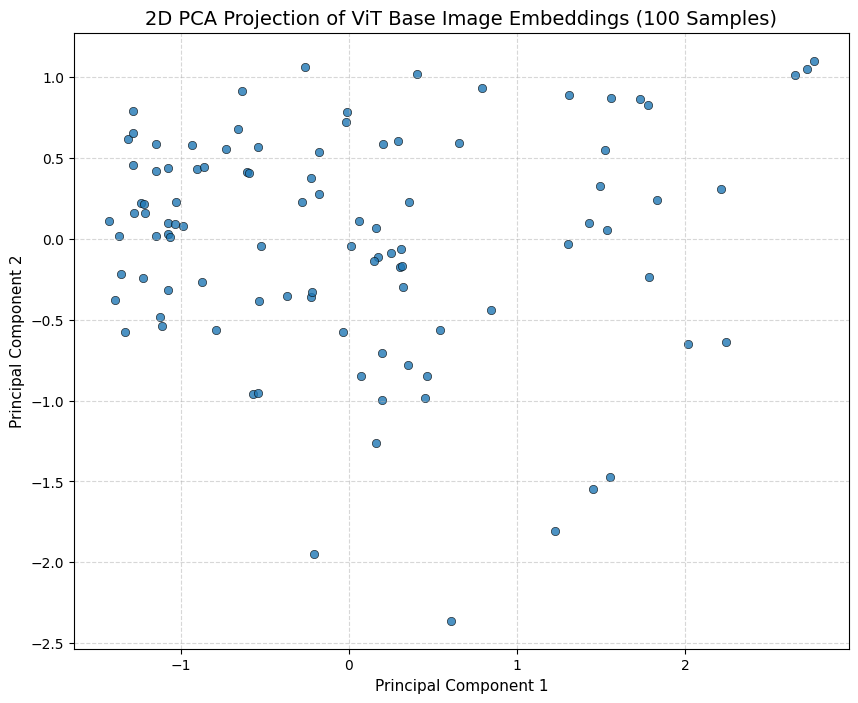

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

# Convert embeddings to a numpy array if not already
if isinstance(embeddings, list):
    embeddings_arr = np.array(embeddings)
else:
    embeddings_arr = embeddings

# Use PCA to project the 768-dimensional embeddings to 2D
pca = PCA(n_components=2, random_state=42)
embeddings_2d = pca.fit_transform(embeddings_arr)

# Create a DataFrame for easy plotting
plot_df = pd.DataFrame({
    'PCA 1': embeddings_2d[:, 0],
    'PCA 2': embeddings_2d[:, 1],
    'image_name': image_names
})

# Plot the embeddings
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PCA 1',
    y='PCA 2',
    data=plot_df,
    alpha=0.8,
    edgecolor='k'
)

plt.title('2D PCA Projection of ViT Base Image Embeddings (100 Samples)', fontsize=14)
plt.xlabel('Principal Component 1', fontsize=11)
plt.ylabel('Principal Component 2', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [31]:
# Display the image names alongside their 2D PCA projected vectors
print("First 10 images with their 2D PCA projected vectors:")
for idx, row in plot_df.head(10).iterrows():
    print(f"{row['image_name']}: [{row['PCA 1']:.4f}, {row['PCA 2']:.4f}]")

First 10 images with their 2D PCA projected vectors:
11560216_page_seg_0.png: [-1.0246, 0.2271]
12845546_page_seg_0.png: [-1.3557, -0.2193]
12845546_page_seg_1.png: [0.3105, -0.0627]
12845546_page_seg_2.png: [1.8336, 0.2435]
12845546_page_seg_3.png: [-0.2255, 0.3745]
15349635_page_seg_0.png: [-0.6339, 0.9119]
15349635_page_seg_1.png: [-0.9003, 0.4319]
13140232_page_seg_0.png: [-1.3304, -0.5787]
13140232_page_seg_1.png: [-0.8755, -0.2675]
13140232_page_seg_2.png: [1.3014, -0.0324]


In [32]:
print(f"Raw ViT base embeddings shape: {embeddings.shape}")
print(f"Raw embeddings dimension (per image): {embeddings.shape[1]}")
print(f"Number of images processed: {embeddings.shape[0]}")
print(f"\n2D PCA projected embeddings shape: {embeddings_2d.shape}")

Raw ViT base embeddings shape: (100, 768)
Raw embeddings dimension (per image): 768
Number of images processed: 100

2D PCA projected embeddings shape: (100, 2)


# Phase 1 — Supervised visual + question QA baseline

**Goal:** predict the ground-truth `answer` from `question` and candidate subpage/table images associated with its parent Wikipedia page. This is a **trainable** baseline, unlike the preceding frozen ViT feature-extraction/PCA cells.

**Model:** frozen pretrained ViT (`google/vit-base-patch16-224-in21k`) + frozen BERT (`bert-base-uncased`) → learned question-conditioned attention over candidate visual embeddings → answer classifier. Only the fusion and classification layers are trained.

**Caveats:** This is *closed-vocabulary classification*, not open-ended answer generation. An answer unseen in training cannot be predicted. The code reports answer-vocabulary coverage separately. Candidate tables are **not assumed to be ground-truth evidence**; we associate them through the parent page and learn question-conditioned weighting. Visual inputs are resized to 224×224, so small text may be lost. For a stronger model, progress to patch-token cross-attention and a text decoder.

Run the existing notebook through the subpage/table mapping cells (11 and 13) first. The 100-image embedding/PCA cells are optional; this section creates its own complete cached features.

In [33]:
# 1. Build a QA record per question, with candidate subpages/table crops from its parent image.
# Start small for a Colab baseline; increase MAX_QA after validating the pipeline.
import ast, re, random, hashlib
import numpy as np
import pandas as pd
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MAX_QA = {"train": 2000, "val": 300, "test": 300}
MAX_SUBPAGES = 2
MAX_TABLES = 3
MAX_ANSWERS = 500  # most frequent TRAIN answers; adjust after reviewing coverage
QA_OUT = ROOT / "embeddings" / "vit_bert_qa_baseline"
QA_OUT.mkdir(parents=True, exist_ok=True)

def normalize_answer(x):
    if x is None: return ""
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) != 1: return ""  # exclude ambiguous/multiple-answer labels for initial baseline
        x = x[0]
    if isinstance(x, str) and x.strip().startswith("["):
        try:
            v = ast.literal_eval(x)
            if isinstance(v, list):
                if len(v) != 1: return ""
                x = v[0]
        except (ValueError, SyntaxError): pass
    if pd.isna(x): return ""
    return " ".join(re.sub(r"[^\w\s]", " ", str(x).lower()).split())

qa_splits = {}
for split, source in datasets.items():
    required = {"image", "question", "answer"}
    if not required.issubset(source.columns):
        raise KeyError(f"{split}: missing {required - set(source.columns)}; columns={list(source.columns)}")
    d = source[["image", "question", "answer"]].dropna().copy()
    d["answer_norm"] = d["answer"].map(normalize_answer)
    d = d[(d["answer_norm"] != "") & (d["question"].astype(str).str.strip() != "")]
    d = d.drop_duplicates(subset=["image", "question", "answer_norm"])
    d = d.sample(n=min(MAX_QA[split],len(d)),random_state=SEED).reset_index(drop=True)
    qa_splits[split] = d
    print(split, "QA examples:", len(d), "unique parents:", d.image.nunique())

# Index visual evidence by parent. Tables and subpages may repeat across QA examples;
# their frozen embeddings will be computed only once.
visual_by_parent = {}
for split in subpage_datasets:
    for r in subpage_datasets[split].itertuples(index=False):
        visual_by_parent.setdefault(str(r.image), {})["S:" + str(r.subpage)] = {
            "kind":"subpage", "path":str(r.subpage_path)}
    for r in table_datasets[split].itertuples(index=False):
        visual_by_parent.setdefault(str(r.image), {})["T:" + str(r.table_id)] = {
            "kind":"table", "path":str(r.subpage_path),
            "box":(int(r.xmin),int(r.ymin),int(r.xmax),int(r.ymax))}

def candidates(parent):
    entries = visual_by_parent.get(str(parent), {})
    tables = sorted(k for k in entries if k.startswith("T:"))[:MAX_TABLES]
    subpages = sorted(k for k in entries if k.startswith("S:"))[:MAX_SUBPAGES]
    return tables + subpages  # prefer table crops, retain subpage context

for split, d in qa_splits.items():
    d["visual_ids"] = d["image"].map(candidates)
    qa_splits[split] = d[d.visual_ids.map(bool)].reset_index(drop=True)
    print(split, "with visual evidence:",len(qa_splits[split]))

# Important: a QA split does not guarantee disjoint parent pages.
for a,b in [("train","val"),("train","test"),("val","test")]:
    overlap = set(qa_splits[a].image) & set(qa_splits[b].image)
    print(f"Parent overlap {a}/{b}: {len(overlap)}")
print("NOTE: If parent overlap is nonzero, report it; for page-generalization evaluation, rebuild page-disjoint splits.")


train QA examples: 2000 unique parents: 1742
val QA examples: 300 unique parents: 295
test QA examples: 300 unique parents: 297
train with visual evidence: 2000
val with visual evidence: 300
test with visual evidence: 300
Parent overlap train/val: 59
Parent overlap train/test: 49
Parent overlap val/test: 11
NOTE: If parent overlap is nonzero, report it; for page-generalization evaluation, rebuild page-disjoint splits.


In [34]:
# 2. Build a train-only answer vocabulary and measure coverage.
from collections import Counter
train_counts = Counter(qa_splits["train"]["answer_norm"])
answer_vocab = [ans for ans,_ in train_counts.most_common(MAX_ANSWERS)]
answer_to_id = {a:i for i,a in enumerate(answer_vocab)}
print("Answer classes:",len(answer_vocab))
for split, d in qa_splits.items():
    d["label"] = d["answer_norm"].map(answer_to_id)
    coverage = d["label"].notna().mean() if len(d) else 0
    print(f"{split}: {coverage:.1%} label coverage ({d.label.notna().sum()}/{len(d)})")
# Train only examples whose answer is in the training answer vocabulary.
train_qa = qa_splits["train"].dropna(subset=["label"]).copy()
if len(train_qa) < 2 or len(answer_vocab) < 2:
    raise ValueError("Not enough labeled training examples/classes. Inspect answer formatting or raise MAX_QA.")


Answer classes: 500
train: 75.8% label coverage (1515/2000)
val: 56.0% label coverage (168/300)
test: 51.3% label coverage (154/300)


In [36]:
# 3. Cache frozen ViT features for ALL unique candidate images in this baseline.
# Cache is persisted to Drive and reused across Colab sessions.
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import pickle

needed_ids = sorted({vid for d in qa_splits.values() for ids in d.visual_ids for vid in ids})
FEATURE_FILE = QA_OUT / f"vit_features_q{MAX_QA['train']}.pkl"

# Load existing features if available
if FEATURE_FILE.exists():
    with open(FEATURE_FILE, "rb") as f:
        visual_features = pickle.load(f)
else:
    visual_features = {}

missing_ids = [vid for vid in needed_ids if vid not in visual_features]

# Prepare dataset for extraction
if missing_ids:
    records = []
    for vid in missing_ids:
        entries = [visual_by_parent[parent][vid] for parent in visual_by_parent if vid in visual_by_parent[parent]]
        if entries:
            entry = entries[0]
            records.append({"subpage": vid, "subpage_path": entry["path"], "xmin": entry.get("box", [0,0,0,0])[0], "ymin": entry.get("box", [0,0,0,0])[1], "xmax": entry.get("box", [0,0,0,0])[2], "ymax": entry.get("box", [0,0,0,0])[3]})

    import pandas as pd
    df_missing = pd.DataFrame(records)
    if not df_missing.empty:
        modes = ["subpage" if any(vid.startswith("S:") for vid in missing_ids) else "table"]
        # Fallback to general extraction
        for mode in ["subpage", "table"]:
            sub_df = df_missing[df_missing["subpage"].str.startswith("S:" if mode == "subpage" else "T:")]
            if sub_df.empty:
                continue
            # Map back fields required by WikiDTVisualDataset
            sub_df = sub_df.rename(columns={"subpage": "table_id" if mode == "table" else "subpage"})
            loader = DataLoader(WikiDTVisualDataset(sub_df, processor, mode=mode), batch_size=32, shuffle=False)
            model.eval()
            with torch.inference_mode():
                for batch in tqdm(loader, desc=f"Caching {mode} embeddings"):
                    outputs = model(pixel_values=batch["pixel_values"].to(DEVICE))
                    feats = outputs.last_hidden_state[:, 0, :].cpu().numpy()
                    for item_id, feat in zip(batch["item_id"], feats):
                        key = ("S:" if mode == "subpage" else "T:") + item_id
                        visual_features[key] = feat.astype(np.float32)

        with open(FEATURE_FILE, "wb") as f:
            pickle.dump(visual_features, f)

print("Visual features available:", len(visual_features))

Caching subpage embeddings:   0%|          | 0/128 [00:00<?, ?it/s]

Caching table embeddings:   0%|          | 0/205 [00:00<?, ?it/s]

Visual features available: 10609


In [37]:
# 4. Cache frozen BERT question vectors (one per unique question).
from transformers import AutoTokenizer, AutoModel
BERT_NAME = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).to(DEVICE).eval()
for p in bert_model.parameters(): p.requires_grad_(False)
QUESTION_FILE = QA_OUT / f"bert_question_features_q{MAX_QA['train']}.pkl"
if QUESTION_FILE.exists():
    with open(QUESTION_FILE,"rb") as f: question_features=pickle.load(f)
else: question_features={}
questions = sorted({str(q) for d in qa_splits.values() for q in d.question})
missing_q = [q for q in questions if q not in question_features]
with torch.inference_mode():
    for start in tqdm(range(0,len(missing_q),32),desc="Cache BERT questions"):
        chunk=missing_q[start:start+32]
        tok=bert_tokenizer(chunk,padding=True,truncation=True,max_length=96,return_tensors="pt")
        tok={k:v.to(DEVICE) for k,v in tok.items()}
        hidden=bert_model(**tok).last_hidden_state
        mask=tok["attention_mask"].unsqueeze(-1)
        pooled=((hidden*mask).sum(1)/mask.sum(1).clamp(min=1)).cpu().numpy()
        for q,v in zip(chunk,pooled): question_features[q]=v.astype(np.float32)
if missing_q:
    with open(QUESTION_FILE,"wb") as f: pickle.dump(question_features,f)
print("Question vectors available:",len(question_features))
# Release encoder memory before training fusion head.
bert_model.to("cpu")
if DEVICE == "cuda": torch.cuda.empty_cache()


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Cache BERT questions: 0it [00:00, ?it/s]

Question vectors available: 2599


In [39]:
# 5. Train a question-conditioned attention model with variable numbers of candidate images.
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch
import pandas as pd

MAX_CANDIDATES = MAX_SUBPAGES + MAX_TABLES

class QAFusionDataset(Dataset):
    def __init__(self, d):
        self.df = d.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        v = np.zeros((MAX_CANDIDATES, 768), dtype=np.float32)
        m = np.zeros(MAX_CANDIDATES, dtype=bool)
        for j, vid in enumerate(r.visual_ids[:MAX_CANDIDATES]):
            # Fallback to double-prefixed keys (e.g., 'T:T:...') if the single prefixed key isn't present
            if vid in visual_features:
                v[j] = visual_features[vid]
                m[j] = True
            else:
                prefix = "S:" if vid.startswith("S:") else "T:"
                fallback_key = prefix + vid
                if fallback_key in visual_features:
                    v[j] = visual_features[fallback_key]
                    m[j] = True
                else:
                    # Default zero vector if embedding is missing entirely
                    v[j] = np.zeros(768, dtype=np.float32)
                    m[j] = False

        return {
            "q": torch.tensor(question_features[str(r.question)]),
            "v": torch.from_numpy(v),
            "mask": torch.from_numpy(m),
            "label": torch.tensor(int(r.label) if pd.notna(r.label) else -1, dtype=torch.long)
        }

class ViTBertAnswerClassifier(nn.Module):
    def __init__(self, n_classes, hidden=256):
        super().__init__()
        self.q_proj = nn.Linear(768, hidden)
        self.v_proj = nn.Linear(768, hidden)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, n_classes)
        )

    def forward(self, q, v, mask):
        qh = self.q_proj(q)
        vh = self.v_proj(v)
        scores = (vh * qh.unsqueeze(1)).sum(-1) / (qh.shape[-1] ** 0.5)
        weights = torch.softmax(scores.masked_fill(~mask, -1e9), dim=1)
        attended = (weights.unsqueeze(-1) * vh).sum(1)
        return self.classifier(torch.cat([qh, attended], dim=-1))

qa_model = ViTBertAnswerClassifier(len(answer_vocab)).to(DEVICE)
optimizer = torch.optim.AdamW(qa_model.parameters(), lr=3e-4, weight_decay=0.01)
loss_fn = nn.CrossEntropyLoss()
train_loader = DataLoader(QAFusionDataset(train_qa), batch_size=32, shuffle=True)
val_known = qa_splits["val"].dropna(subset=["label"])
val_loader = DataLoader(QAFusionDataset(val_known), batch_size=64, shuffle=False)

def run_epoch(loader, train=False):
    qa_model.train(train)
    losses = []; correct = 0; total = 0
    for batch in loader:
        q = batch["q"].to(DEVICE)
        v = batch["v"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)
        labels = batch["label"].to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = qa_model(q, v, mask)
            loss = loss_fn(logits, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        losses.append(loss.item() * len(labels))
        correct += (logits.argmax(1) == labels).sum().item()
        total += len(labels)
    return (sum(losses) / total if total else float("nan"), correct / total if total else float("nan"))

history = []; best_val = -1
for epoch in range(1, 9):
    train_loss, train_acc = run_epoch(train_loader, True)
    if len(val_known):
        val_loss, val_acc = run_epoch(val_loader, False)
    else:
        val_loss, val_acc = float("nan"), float("nan")
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc_known": val_acc
    })
    print(f"epoch {epoch}: train loss {train_loss:.3f}, acc {train_acc:.3f}; val known-label acc {val_acc:.3f}")
    if len(val_known) and val_acc > best_val:
        best_val = val_acc
        torch.save(qa_model.state_dict(), QA_OUT / "best_fusion_classifier.pt")

if best_val >= 0:
    qa_model.load_state_dict(torch.load(QA_OUT / "best_fusion_classifier.pt", map_location=DEVICE, weights_only=True))
pd.DataFrame(history).to_parquet(QA_OUT / "training_history.parquet", index=False)

epoch 1: train loss 4.572, acc 0.383; val known-label acc 0.625
epoch 2: train loss 3.714, acc 0.399; val known-label acc 0.625
epoch 3: train loss 3.557, acc 0.399; val known-label acc 0.625
epoch 4: train loss 3.462, acc 0.399; val known-label acc 0.625
epoch 5: train loss 3.367, acc 0.415; val known-label acc 0.655
epoch 6: train loss 3.266, acc 0.431; val known-label acc 0.690
epoch 7: train loss 3.157, acc 0.446; val known-label acc 0.685
epoch 8: train loss 3.050, acc 0.460; val known-label acc 0.696


In [40]:
# 6. Evaluate normalized Exact Match on validation/test, including out-of-vocabulary answers.
# Unknown answers are counted as incorrect; conditional accuracy on known answers is also shown.
@torch.inference_mode()
def evaluate_split(split):
    d=qa_splits[split].reset_index(drop=True)
    loader=DataLoader(QAFusionDataset(d),batch_size=64,shuffle=False)
    qa_model.eval(); predictions=[]
    for batch in loader:
        logits=qa_model(batch["q"].to(DEVICE),batch["v"].to(DEVICE),batch["mask"].to(DEVICE))
        predictions.extend([answer_vocab[j] for j in logits.argmax(1).cpu().tolist()])
    result=d[["image","question","answer","answer_norm"]].copy()
    result["prediction"]=predictions
    result["correct"]=result["prediction"]==result["answer_norm"]
    result["in_train_vocab"]=result["answer_norm"].isin(answer_to_id)
    coverage=result["in_train_vocab"].mean() if len(result) else float("nan")
    em=result["correct"].mean() if len(result) else float("nan")
    known=result.loc[result.in_train_vocab,"correct"].mean()
    print(f"{split}: n={len(result)}, vocab coverage={coverage:.3f}, overall EM={em:.3f}, EM on known answers={known:.3f}")
    result.to_parquet(QA_OUT/f"{split}_predictions.parquet",index=False)
    return result

val_predictions=evaluate_split("val")
# Test should be run only once after selecting settings using validation.
# Uncomment for final held-out evaluation:
# test_predictions=evaluate_split("test")
display(val_predictions.head(15))


val: n=300, vocab coverage=0.560, overall EM=0.390, EM on known answers=0.696


,image,question,answer,answer_norm,prediction,correct,in_train_vocab
0,18634046_page.png,What is the lowest win % with a 0-2 record and...,no answer,no answer,no answer,True,True
1,14819302_page.png,"After 1986, how many Wins did Lucky Strike Yam...",no answer,no answer,no answer,True,True
2,15622615_page.png,Which date has a round more than 9?,november 21-23,november 21 23,no answer,False,False
3,11073038_page.png,What was the final rank of the Brewers in 1980?,3rd,3rd,no answer,False,False
4,1558809_page.png,How many Winners have Wins of 1 and a Country ...,no answer,no answer,no answer,True,True
5,203_543_page.png,what is the number of channels she has appeare...,no answer,no answer,no answer,True,True
6,12888640_page.png,What was the format in September 1990 for Cata...,12 maxi,12 maxi,1,False,False
7,204_910_page.png,what nationality was the woman who won first p...,no answer,no answer,no answer,True,True
8,203_67_page.png,who was the top team of the apertura 2003 stan...,no answer,no answer,no answer,True,True
9,17100961_page.png,"Which Name has a Round larger than 4, an Overa...",ken barefoot,ken barefoot,no answer,False,False


```markdown
## Save Processed Mapping DataFrames to Google Drive
To avoid re-running the 2+ hour matching and parsing process for subpages and XML table boundaries, we save the completed DataFrames directly back to Google Drive.
```

In [41]:
# Define the directory to save the structured tables
PROCESSED_DATA_DIR = ROOT / "data" / "processed_mappings"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Save subpage datasets (train, val, test)
for split, df_sub in subpage_datasets.items():
    subpage_save_path = PROCESSED_DATA_DIR / f"{split}_subpage_mappings.parquet"
    df_sub.to_parquet(subpage_save_path, index=False)
    print(f"Saved {split} subpage mappings to: {subpage_save_path}")

# Save table datasets (train, val, test)
for split, df_table in table_datasets.items():
    table_save_path = PROCESSED_DATA_DIR / f"{split}_table_mappings.parquet"
    df_table.to_parquet(table_save_path, index=False)
    print(f"Saved {split} table mappings to: {table_save_path}")

print("\nAll mapping DataFrames have been safely stored on Google Drive!")

Saved train subpage mappings to: /content/drive/MyDrive/WikiDT_Persistent/data/processed_mappings/train_subpage_mappings.parquet
Saved val subpage mappings to: /content/drive/MyDrive/WikiDT_Persistent/data/processed_mappings/val_subpage_mappings.parquet
Saved test subpage mappings to: /content/drive/MyDrive/WikiDT_Persistent/data/processed_mappings/test_subpage_mappings.parquet
Saved train table mappings to: /content/drive/MyDrive/WikiDT_Persistent/data/processed_mappings/train_table_mappings.parquet
Saved val table mappings to: /content/drive/MyDrive/WikiDT_Persistent/data/processed_mappings/val_table_mappings.parquet
Saved test table mappings to: /content/drive/MyDrive/WikiDT_Persistent/data/processed_mappings/test_table_mappings.parquet

All mapping DataFrames have been safely stored on Google Drive!


## Interpreting this baseline and next experiments

- **Input X:** BERT question vector and a variable-length set (padded to five) of ViT CLS embeddings for candidate tables/subpages from the same parent page. The learned attention scores weight visual candidates *conditioned on the question*.
- **Target y:** normalized answer string, mapped to an integer class from the training split only.
- **Training:** frozen ViT/BERT; only attention projections and the answer classifier update. Cached features are reused when the same page appears in many questions.
- **Metrics:** overall normalized Exact Match, EM restricted to answers represented in the training vocabulary, and answer-vocabulary coverage. Overall EM is the primary score for this limited baseline.
- **Important:** The `MAX_QA` samples are small randomized subsets; a single QA split can contain the same page as another split. This notebook reports parent overlap, but **does not repair leakage**. For a rigorous unseen-page benchmark, create page-disjoint splits *before* feature caching/training, and do not tune on test.
- **Next comparisons aligned with the proposal:** OCR text + pretrained QA baseline; patch-token cross-attention rather than CLS pooling; Swin encoder; Pix2Struct/Donut document QA; generative decoder for unseen answers; retrieval Recall@K when verified relevant table labels are available.

**Execution:** run mapping cells 9–13, encoder initialization cell 15, then the new Phase 1 cells. The old 100-image embedding and PCA cells are optional.